# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>

## IMPORTANT: Guidelines for a proper conduct of the exercises
1. you should create code that is correct, simple, well organized, indented, commented, which uses self-explanatory names for variables and that is numerically efficient.
2. I expect a responsible interaction during the exercises: the questions should be more related to the conduction of the exercises and to the meaning of the results obtained than to the computational problems. Bugs are usual in coding; for this reason, sooner or later, one should learn to deal with them by oneself ... if you'll be able to, it will be your main achievement in this Laboratory!

## <span style="color:blue">  Numerical exercises 1</span>

### Exercise 01.1
- Test the Pseudo-Random Number generator downloaded from the NSL Ariel web site by estimating:

1. $\langle r \rangle = \int_0^1 r dr = 1/2$. <font color="red">Make a picture of the estimation of $\langle r \rangle$ and its uncertainty (which corresponds to Standard Deviation of the mean for the estimation of $\langle r \rangle$) with a large number of *throws* $M$ (e.g. $M\ge 10^4$) as a function of the number of blocks, $N$</font> (see below: Computing statistical uncertainties).

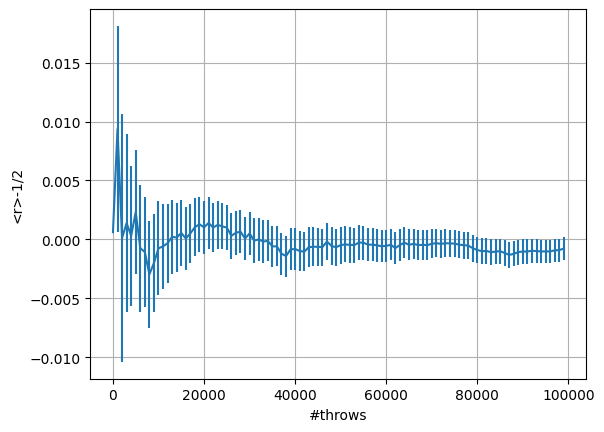

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

def error(AV,AV2,n):  # Function for statistical uncertainty estimation
    if n==0:
        return 0
    else:
        return math.sqrt((AV2[n] - AV[n]**2)/n)

M=100000              # Total number of throws
N=100                 # Number of blocks
L=int(M/N)            # Number of throws in each block, please use for M a multiple of N
np.random.seed(1)     # Fixing random seed for reproducibility
r = np.random.rand(M) # U[0,1) uniform distribution
x = np.arange(N)      # [0,1,2,...,N-1]
ave = np.zeros(N)
av2 = np.zeros(N)
sum_prog = np.zeros(N)
su2_prog = np.zeros(N)
err_prog = np.zeros(N)

for i in range(N):
    sum1 = 0
    sum2 = 0 #PROVA per far vedere come si può sbagliare ad interpretare il calcolo di A_i^2
    for j in range(L):
        k = j+i*L
        sum1 += r[k]
        sum2 += r[k]*r[k] #PROVA
    ave[i] = sum1/L     # r_i 
    #av2[i] = sum2/L     # (r_i)^2 #PROVA
    av2[i] = (ave[i])**2 # (r_i)^2 

for i in range(N):
    for j in range(i+1):
        sum_prog[i] += ave[j] # SUM_{j=0,i} r_j
        su2_prog[i] += av2[j] # SUM_{j=0,i} (r_j)^2
    sum_prog[i]/=(i+1) # Cumulative average
    su2_prog[i]/=(i+1) # Cumulative square average
    err_prog[i] = error(sum_prog,su2_prog,i) # Statistical uncertainty
    
x*=L # Number of throws = block * (Number of throws in each block)
plt.errorbar(x,sum_prog-0.5,yerr=err_prog)
plt.xlabel('#throws')
plt.ylabel('<r>-1/2')
plt.grid(True)
plt.show()

2. $\sigma^2 = \int_0^1 (r-1/2)^2 dr = 1/12$. <font color="red">Make a picture of the estimation of $\sigma^2$ and its uncertainty (which corresponds to Standard Deviation of the mean for the estimation of $\langle (r-1/2)^2 \rangle$) with a large number of *throws* $M$ (e.g. $M\ge 10^4$) as a function of the number of blocks, $N$</font> (see below: Computing statistical uncertainties).

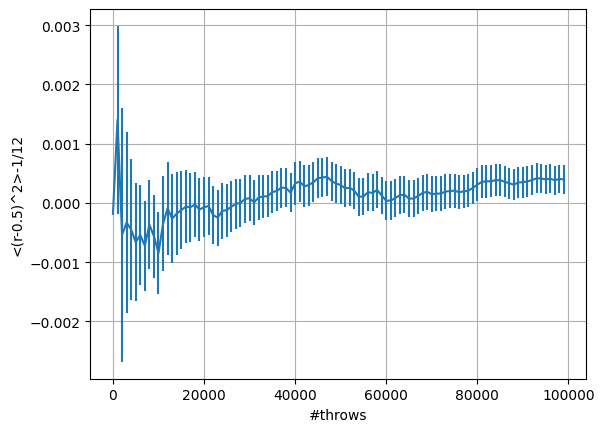

In [2]:
# Continue using variables and functions of the previous code cell
ave = np.zeros(N)
av2 = np.zeros(N)
sum_prog = np.zeros(N)
su2_prog = np.zeros(N)
err_prog = np.zeros(N)

for i in range(N):
    sum = 0
    for j in range(L):
        k = j+i*L
        sum += (r[k]-0.5)**2 # Accumulate measures
    ave[i] = sum/L           # Estimate in each block 
    av2[i] = (ave[i])**2 

for i in range(N):
    for j in range(i+1):
        sum_prog[i] += ave[j] 
        su2_prog[i] += av2[j] 
    sum_prog[i]/=(i+1) # Cumulative average
    su2_prog[i]/=(i+1) # Cumulative square average
    err_prog[i] = error(sum_prog,su2_prog,i) # Statistical uncertainty
    
plt.errorbar(x,sum_prog-1/12,yerr=err_prog)
plt.xlabel('#throws')
plt.ylabel('<(r-0.5)^2>-1/12')
plt.grid(True)
plt.show()

The hypothesis is that the numbers $r$ are drawn from a uniform distribution. In Statistics we cannot prove that some random events are drawn from a particular distribution (Note, in fact, that such hypothesis is false: pseudo-random numbers are drawn from a deterministic algorithm!); we can try to estimate the probability that $r$ **are not** drawn from a uniform distribution. If this probability is low, we can safely reject this last hypothesis.

Pearson's cumulative test statistic $\chi^2$ is a measure of the error between observations, $O_i$, and expected values, $E_i$:
$$\chi^2 = \sum_{i} \frac{\left( O_i - E_i \right)^2}{E_i}$$
The numerator is a squared distance between observations, $O_i$, and expected values, $E_i$, and thus should be compared (at the denominator) with the expected squared fluctuations (variance) of the relative distribution. Why variance = $E_i$? 
The probability of getting exactly $k$ (independent) successes, each one with probability $p$, in $n$ trials is given by the Binomial distribution (see <a href="https://en.wikipedia.org/wiki/Binomial_distribution">this Wikipedia link</a>):
$$Pr(X=k) = {{n}\choose{k}} p^k (1-p)^{n-k} = \frac{n!}{k! (n-k)!} p^k (1-p)^{n-k}$$
The average of the Binomial distribution is $\langle X \rangle = np$, the variance is: $\sigma^2 = np (1-p)$. Thus if $p$ is small we have that $\sigma^2 \simeq np$, that is $\sigma^2 \simeq \langle X \rangle$ and this explains the denominator $E_i$ in $\chi^2$


3. Divide $[0,1]$ into $M$ identical sub-intervals and implement the $\chi^2$ test. Obviously, the number of expected events observed in each sub-interval after $n$ *throws*, according to a uniform distribution, is $np = n\times 1/M= n/M$. Fix $M=10^2$ and use for $n$ the first $10^4$ pseudo-random numbers, then the successive $10^4$ pseudo-random numbers, and so on ... 100 times. <font color="red">Plot $\chi^2_j$ for $j=1, ..., 100$</font>. In this case the chi-square statistic is:
$$\chi^2 = \sum_{i=1}^M \frac{\left( n_i - n/M \right)^2}{n/M}$$
We should expect on average that $(n_i - n/M)^2 \simeq n/M$ and thus $\chi^2 \simeq 100$, i.e. the number of sub-intervals.
A larger value of $\chi^2$ indicates that the hypothesis ($n_i$ are drawn from a uniform distribution) is rather unlikely ... <font color="red">but before judging</font>, you could compare the histogram of the values obtained for $\chi^2_j$ with the true probability distribution (see: <a href="https://en.wikipedia.org/wiki/Chi-squared_distribution">this Wikipedia link</a>).

### Exercise 01.2
- Extend Pseudo-Random Number generator downloaded from the NSL Ariel web site and check the Central Limit Theorem:

1. <font color="red">Add two probability distributions</font> by using the **method of the inversion of the cumulative distribution** to sample from a **generic** <font color="red">exponential distribution</font>, $p(x) = \lambda \exp(-\lambda x)$, $x\in [0;+\infty]$ (see <a href="https://en.wikipedia.org/wiki/Exponential_distribution">this Wikipedia link</a>), and a **generic** <font color="red">Cauchy-Lorentz distribution</font> $p(x)=\frac{1}{\pi}\frac{\Gamma}{(x-\mu)^2+\Gamma^2}$, $x\in [-\infty;+\infty]$ (see <a href="https://en.wikipedia.org/wiki/Cauchy_distribution">this Wikipedia link</a>).
2. <font color="red">Make 3 pictures</font> with the histograms obtained filling them with $10^4$ realizations of $S_N = \frac{1}{N}\sum_{i=1}^N x_i$ (for $N=1, 2, 10, 100$), being $x_i$ a random variable sampled throwing a *standard* dice (fig.1), an *exponential* dice (fig.2, use $\lambda=1$) and a *Lorentzian* dice (fig.3, use $\mu=0$ and $\Gamma=1$).

Note tha you can try to fit the case $N=100$ with a Gaussian for standard and exponential dices, whereas you should use a Cauchy-Lorentz distribution for the last case.

### Exercise 01.3
- **Simulate** the Buffon’s experiment (see LSN_Lecture_00, supplementary material):  A needle of length $L$ is thrown at random onto a horizontal plane ruled with straight lines a distance $d$ (must be $d > L$, but do not use $d\gg L$ otherwise $P\ll 1$) apart. The probability $P$ that the needle will intersect one of these lines is: $P = 2L/\pi d$. This could be used to evaluate $\pi$ from throws of the needle: if the needle is thrown down $N_{thr}$ times and is observed to land on a line $N_{hit}$ of those times, we can make an estimate of $\pi$ from
$$\pi = \frac{2L}{Pd} = \lim_{N_{thr} \to \infty}\frac{2LN_{thr}}{N_{hit}d}$$
<font color="red">Make a picture of the estimation of $\pi$ and its uncertainty (Standard Deviation of the mean) with a large number of *throws* $M$ as a function of the number of blocks, $N$</font> (see below: Computing statistical uncertainties). If possible, do not use $\pi$ to evaluate $\pi$.

### <span style="color:blue">Computing statistical uncertainties: the blocking method</span>
- A fundamental step in every Monte Carlo calculation is the estimation of its statistical uncertainty, **it's a must!** Your task would not be completed if you had not calculated it.


In computing the statistical uncertainties, i.e. the standard deviation of the mean, you need an estimation of the variance $\sigma^2$, the second central moment. First of all note that the variance can be computed from
$$\sigma^2_A := \langle (A-\langle A\rangle)^2\rangle = \langle A^2 \rangle -\langle A\rangle^2 $$
What is the best way to estimate $\sigma^2_A$? Imagine that your Monte Carlo estimation of $A$ is obtained from a calculation which uses $M$ Monte Carlo "steps" (intentionally, here I am generic because what is a single "step" in a Monte Carlo calculation strictly depends on the specific calculation); you can always divide such $M$ Monte Carlo "steps" in $N$ blocks, with $N<M$. In each block, you can use your $M/N$ Monte Carlo "steps" to obtain an estimate of $A$, let me call it $A_i$ with $i=1,N$, and then you have also $A^2_i$ with $i=1,N$.
At this point everything becomes clear:
$$ \langle A^2 \rangle \simeq \frac{1}{N} \sum_{i=1}^N A^2_i \quad \quad \langle A\rangle^2 \simeq \left( \frac{1}{N} \sum_{i=1}^N A_i \right)^2 $$
and finally the statistical uncertainty with $N$ :
$$\frac{\sigma}{\sqrt{N-1}} \simeq \sqrt{\frac{1}{N-1} \left[ \frac{1}{N} \sum_{i=1}^N A^2_i - \left( \frac{1}{N} \sum_{i=1}^N A_i \right)^2 \right]} $$


- <font color="blue">In a Monte Carlo calculation, you can use the arguments above to outputting an estimate of A and its statistical uncertainty on the fly, during your calculation. You will be able to do this every $M/N$ steps, and thus, in the end, $N$ times</font>. Note that after the first $M/N$ Monte Carlo steps, at the end of the first block, your estimation of the uncertainty is not computable, so set it to zero and compute it only from the second block. **Question**: $N$ can be chosen in many ways ... what are the limitations regarding this choice?

# <span style="color:green"> RESULTS: </span>
## Exercise 1.1 

The purpose of these exercises is to evaluate the performance of the provided pseudo-random number generator. 

To verify that the generated numbers are uniformly distributed over the interval $[0,1]$, we tested their statistical properties by computing the progressive estimation and uncertainty of the sample mean $\langle r \rangle$ and variance $\sigma^2 = \left\langle \left(r - \frac{1}{2}\right)^2 \right\rangle$.

To evaluate the statistical uncertainties, we implemented the Data Blocking method. The total data set is divided into $N$ blocks, each containing $L$ steps/measurements. By considering the averages of individual blocks rather than single steps, we eliminate short-range correlations that could otherwise lead to an underestimation of the final error.

The statistical uncertainty (standard error of the mean) for $N$ blocks is calculated as follows:

starting from the variance of the block averages:
$$\sigma^2 = <A^2> - <A>^2$$
where 
$$  <A^2> = \frac{1}{N}\sum_{i=1}^N A_{i}^2  \ \ \ \ \ \   <A> =  \frac{1}{N}\sum_{i=1}^N A_{i}  $$
the statistical uncertainty associated with the progressiveaverage is then given by:
$$ \frac{\sigma}{\sqrt{N-1}} = \sqrt{\frac{\sigma^2}{N-1}} = \sqrt{\frac{1}{N-1} \left[ \frac{1}{N}\sum_{i=1}^N A_{i}^2  - \left( \frac{1}{N}\sum_{i=1}^N A_{i} \right)^2 \right]} $$


###  Progressive Mean

We computed the progressive estimation and uncertainty of the sample mean, comparing it with its theoretical expected value:$$\langle r \rangle = \int_0^1 r \, \mathrm{d}r = \frac{1}{2}$$ Using $M = 10^5$ total pseudo-random numbers divided into $N = 100$ blocks (with $L = 10^3$ steps per block), we evaluated how the progressive mean converges to $1/2$ as the number of blocks increases.

In [3]:
import matplotlib.pyplot as plt
import numpy as np

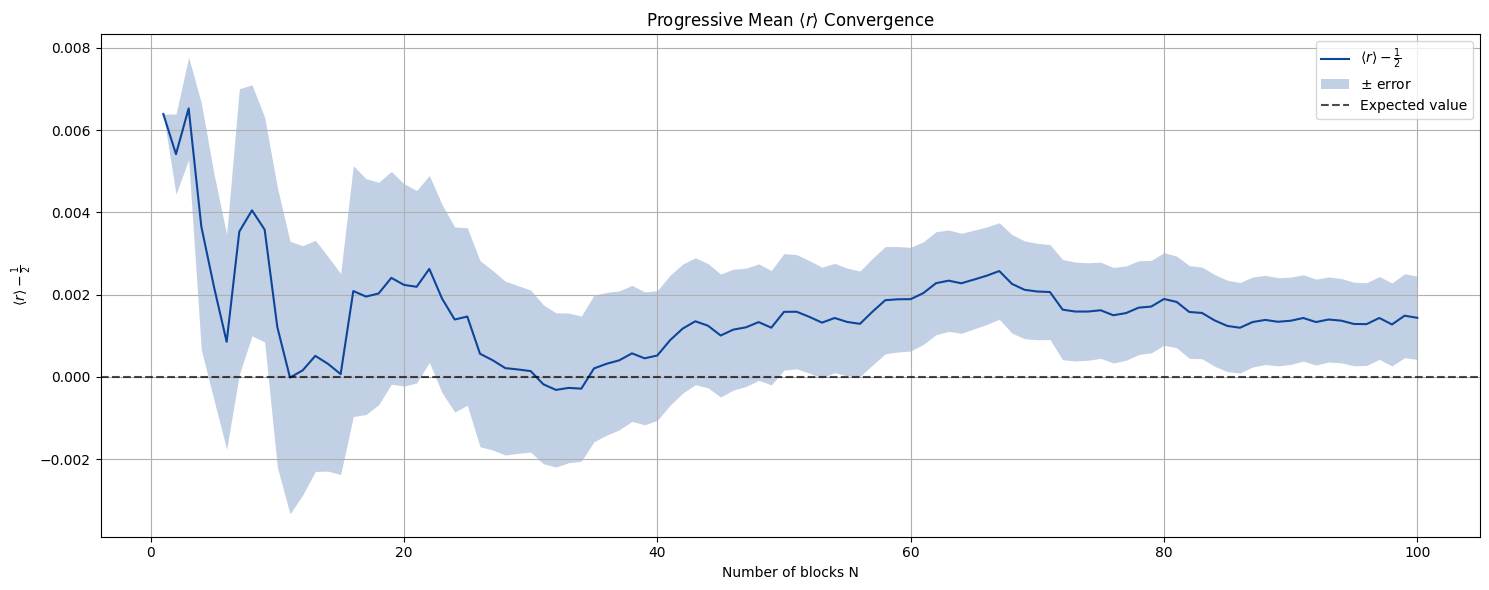

In [4]:
plt.rcParams["figure.figsize"] = (15, 6)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True

block, r_mean, r_error = np.loadtxt(
    "./OUTPUT/data_mean.dat", unpack=True, comments="#"
)

y = r_mean - 0.5

plt.figure()
plt.plot(block, y, "-", color="#0c459a", label=r"$\langle r \rangle - \frac{1}{2}$")
plt.fill_between(block, y - r_error, y + r_error, color="#0c459a", alpha=0.25, linewidth=0, label=r"$\pm$ error")
plt.axhline(0, color="black", linestyle="--", alpha=0.7, label="Expected value")

plt.xlabel("Number of blocks N")
plt.ylabel(r"$\langle r \rangle - \frac{1}{2}$")
plt.title(r"Progressive Mean $\langle r \rangle$ Convergence")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

As shown in the graph, the progressive mean converges toward the expected theoretical value as the number of blocks increases. Furthermore, it can be seen that the final value is fully compatible with zero within $2\sigma$. 

One could notice that for $N = 1$ the statistical uncertainty is identically $0$, that is because calculating the sample standard deviation requires at least two independent block averages ($N \ge 2$) to evaluate the variance around the mean, so the first error was set to $0$ by default.


### Progressive Variance

Similarly, we evaluated the variance of the uniform distribution by computing the progressive estimation of $\sigma^2$ and its statistical uncertainty. The theoretical expected value is given by:$$\sigma^2 = \int_0^1 \left(r - \frac{1}{2}\right)^2 \mathrm{d}r = \frac{1}{12}$$Using the same dataset configuration ($M = 10^5$ total pseudo-random numbers, $N = 100$ blocks, and $L = 10^3$ steps per block), we analyzed the convergence of $\left\langle \left(r - \frac{1}{2}\right)^2 \right\rangle - \frac{1}{12}$ toward zero as a function of the number of blocks $N$.

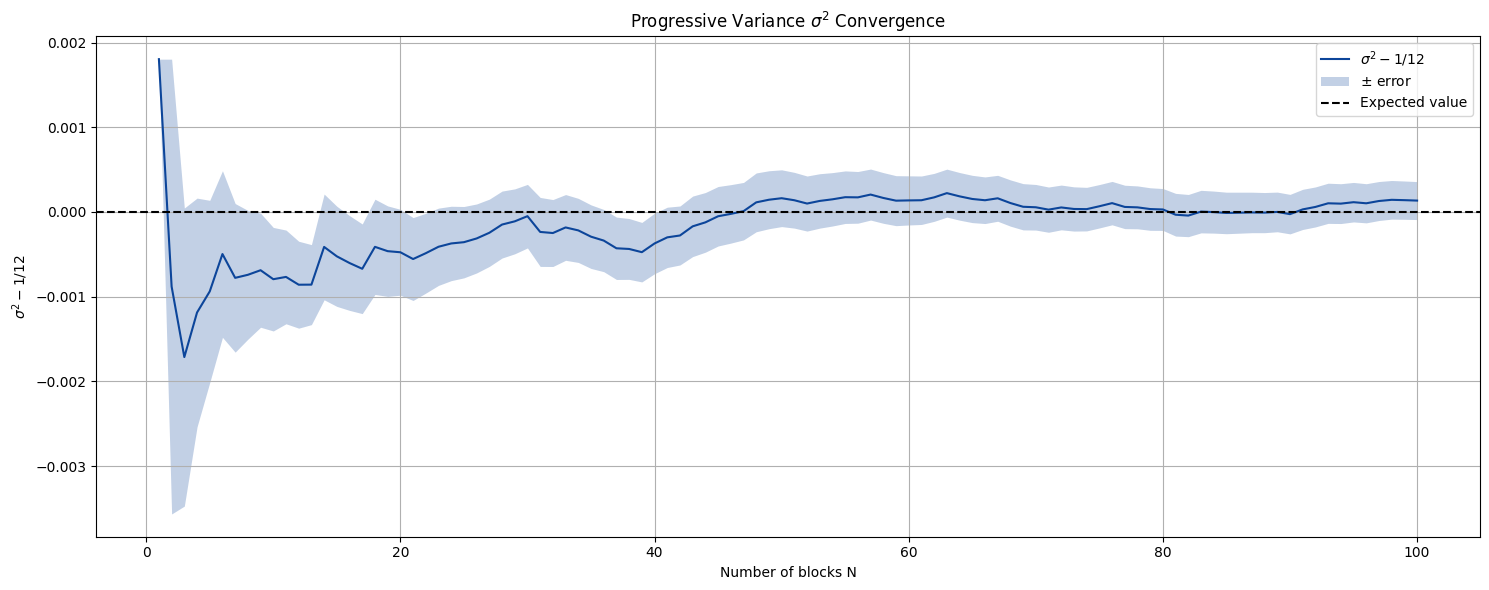

In [5]:
block_s, var_mean, var_error = np.loadtxt(
    "./OUTPUT/data_var.dat", unpack=True, comments="#"
)

y_var = var_mean - (1.0 / 12.0)

plt.figure()
plt.plot(block_s, y_var, "-", color="#0c459a", label=r"$\sigma^2 - 1/12$")
plt.fill_between(block_s, y_var - var_error, y_var + var_error, color="#0c459a", alpha=0.25, linewidth=0, label=r"$\pm$ error")
plt.axhline(0, color="black", linestyle="--", linewidth=1.5, label="Expected value")

plt.xlabel("Number of blocks N")
plt.ylabel(r"$\sigma^2 - 1/12$")
plt.title(r"Progressive Variance $\sigma^2$ Convergence")
plt.legend()
plt.tight_layout()
plt.show()

As observed for the sample mean, the progressive estimation of the variance converges toward the theoretical value $1/12$ as the number of blocks increases. Furthermore, the final value of $\left\langle \left(r - \frac{1}{2}\right)^2 \right\rangle - \frac{1}{12}$ is fully consistent with zero within $1\sigma$.

### Pearson's $\chi^2$ Goodness-of-Fit Test 

Although the previous tests provided good results, it is statistically impossible to prove that the numbers are drawn from a strictly uniform distribution. Rather, through the $\chi^2$ hypothesis test, we evaluate whether there is sufficient evidence to reject the null hypothesis $H_0$ (i.e., that the generator produces uniformly distributed numbers).

If the resulting $\chi^2$ probability ($p$-value) is significantly low (typically $p < 0.05$), we reject the null hypothesis and conclude that the generator is biased. On the other hand, if the probability is sufficiently high, we fail to reject $H_0$, confirming that the observed data are consistent with the assumed uniform distribution.

Pearson's cumulative test statistic $\chi^2$ measures the discrepancy between observed counts $O_i$ and theoretical expected values $E_i$, normalized by the variance $\sigma^2$ of the counting process:
$$\chi^2 = \sum_{i} \frac{\left( O_i - E_i \right)^2}{\sigma^2}$$
To test the uniform distribution of pseudo-random numbers in the interval $[0,1)$, we used the following experimental setup:
The test was iterated $j=100$ times; the unit interval was divided into $M = 100$ identical sub-intervals each with $p = 1/M = 0.01$ and for each iteration $j$, we sampled $n = 10^4$ pseudo-random numbers.

The probability of finding $k$ numbers in a specific sub-interval follows a Binomial distribution:
$$Pr(X=k) = \binom{n}{k} p^k (1-p)^{n-k} = \frac{n!}{k! (n-k)!} p^k (1-p)^{n-k}$$
with mean $\langle X \rangle = np = E_i$ and variance $\sigma^2 = np(1-p)$. Because $p = 1/M \ll 1$ (for $M = 100$, $p = 0.01$), the factor $(1-p) \approx 1$, and the variance simplifies to: $\sigma^2 \simeq np = E_i$. 

The $\chi^2$ expression reduces to:
$$\chi^2 = \sum_{i=1}^M \frac{(n_i - E_i)^2}{E_i} = \sum_{i=1}^M \frac{(n_i - n/M)^2}{n/M} $$

##### Expected Outcomes:
For $M = 100$ bins and $n = 10^4$ draws per test, $E_i = n/M = 100$. On average, the squared deviation $(n_i - E_i)^2$ is expected to be of the order of $E_i$. Consequently, the expected value for $M = 100$ degrees of freedom is: $\langle \chi^2 \rangle \simeq M = 100$ with a theoretical standard deviation of $\sigma_{\chi^2} = \sqrt{2M} \approx 14.14$.

In [6]:
j_test, chi2_values = np.loadtxt(
    "./OUTPUT/data_chi.dat", unpack=True, comments="#"
)

k_df = 100  # dof
expected_mean = k_df
expected_std = np.sqrt(2 * k_df)  # Teoretical standard deviation = sqrt(2*k)

from scipy.stats import chi2

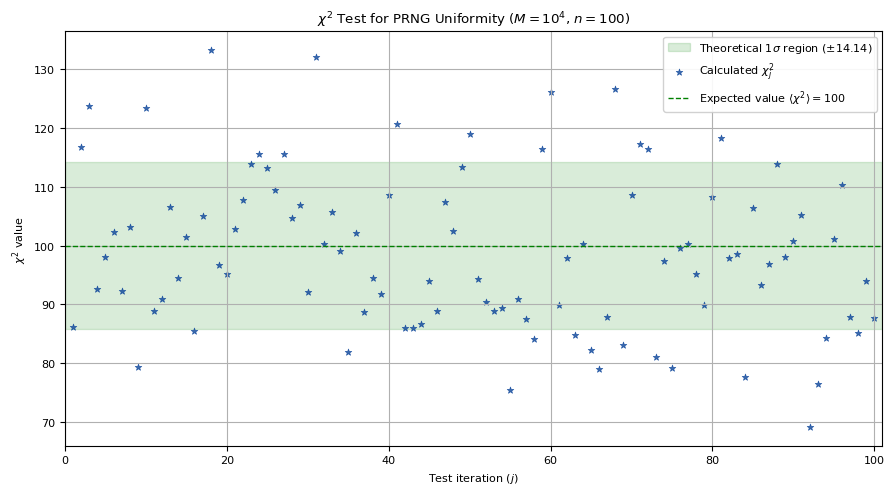

In [7]:
#scatter plot
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 8

# 1sigma band [100 - 14.14, 100 + 14.14]
plt.fill_between( [0, 101], [expected_mean - expected_std] * 2, [expected_mean + expected_std] * 2, color="green", alpha=0.15, label=r"Theoretical $1\sigma$ region ($\pm 14.14$)")

plt.scatter( j_test, chi2_values, marker="*", s=25, color="#0c459a", linewidths=0.5, alpha=0.8, label=r"Calculated $\chi^2_j$")
plt.axhline( expected_mean, color="green", linestyle="--", linewidth=1, label=r"Expected value $\langle \chi^2 \rangle = 100$")

plt.xlim(0, 101)
plt.xlabel("Test iteration ($j$)")
plt.ylabel(r"$\chi^2$ value")
plt.title(r"$\chi^2$ Test for PRNG Uniformity ($M=10^4$, $n=100$)")
plt.legend(loc="upper right", framealpha=0.9)
plt.tight_layout()
plt.show()

From the scatter plot, we observe that the calculated $\chi^2$ values fluctuate consistently around the expected value of $\langle \chi^2 \rangle = 100$. The highlighted $1\sigma$ band ($\pm 14.14$) around the theoretical mean shows that most iterations fall naturally within this range, indicating the absence of long-term drifts or systematic trends.

To further evaluate the nature of these variations and determine whether they stem from pure statistical fluctuations or an underlying generator bias, we constructed the histogram of the 100 calculated $\chi^2$ values to compare this empirical distribution against the theoretical probability density function $\chi^2(k=100)$.

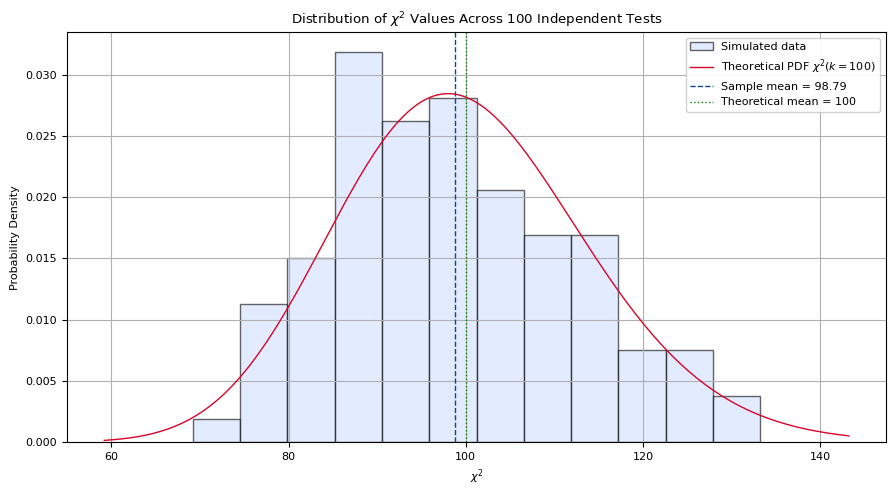

Sample mean of Chi2: 98.79
Sample std of Chi2:  13.51 (Expected: 14.14)
Mean p-value: 0.529


In [8]:
#histogramm
plt.figure(figsize=(9, 5))

p_values = chi2.sf(chi2_values, df=k_df)
count, bins, _ = plt.hist( chi2_values, bins=12, density=True, color="#cfdeffc5", edgecolor="black", alpha=0.6, label="Simulated data")

# Teoretical curve 
x_axis = np.linspace(min(chi2_values) - 10, max(chi2_values) + 10, 200)
plt.plot( x_axis, chi2.pdf(x_axis, df=k_df), color="#d90429", linewidth=1, label=r"Theoretical PDF $\chi^2(k=100)$")

# Linee di media sperimentale e teorica
plt.axvline( np.mean(chi2_values), color="#0c459a", linestyle="--", linewidth=1, label=f"Sample mean = {np.mean(chi2_values):.2f}")
plt.axvline( expected_mean, color="green", linestyle=":", linewidth=1, label="Theoretical mean = 100")

plt.xlabel(r"$\chi^2$")
plt.ylabel("Probability Density")
plt.title(r"Distribution of $\chi^2$ Values Across 100 Independent Tests")
plt.legend(loc="upper right", framealpha=0.9)
plt.tight_layout()
plt.show()

print(f"Sample mean of Chi2: {np.mean(chi2_values):.2f}")
print(f"Sample std of Chi2:  {np.std(chi2_values, ddof=1):.2f} (Expected: {expected_std:.2f})")
print(f"Mean p-value: {np.mean(p_values):.3f}")


The histogram of the simulated data exhibits strong agreement with the theoretical $\chi^2(k=100)$ distribution, further supporting the hypothesis that the generated sequence is uniformly distributed.

Using the survival function of the $\chi^2$ distribution from `scipy.stats`, we evaluated the mean $p$-value across the test iterations, obtaining $p \approx 0.529$. Since this value is well above the significance threshold ($\alpha = 0.05$), we fail to reject the null hypothesis $H_0$, concluding that the pseudo-random number generator is statistically unbiased and suitable for physical simulations.

## Exercise 1.2

In this exercise, we use the pseudo-random number generator to numerically test the Central Limit Theorem (CLT) across three different probability distributions: uniform, exponential, and Cauchy-Lorentz. 

We aim to show how sums of independent variables converge to a Gaussian distribution for the first two distribution, while demonstrating that the CLT breaks down for the Cauchy-Lorentz distribution due to its infinite variance.

#### Theoretical Background: Central Limit Theorem

Let $x_1, x_2, \dots, x_N$ be a set of $N$ independent and identically distributed random variables, each drawn from a probability density function $p(x)$ with a well-defined finite mean $\mu$ and finite variance $\sigma^2$:
$$\langle x_i \rangle = \mu < \infty, \qquad \operatorname{Var}(x_i) = \sigma^2 < \infty$$
The Central Limit Theorem states that as $N \to \infty$, the probability distribution of the means $S_N$ converges asymptotically to a Gaussian distribution $\mathcal{N}(\mu, \sigma_N^2)$ with mean $\mu$ and rescaled variance $\sigma_N^2 = \sigma^2 / N$:

$$P(S_N) \xrightarrow{N \to \infty} \frac{1}{\sqrt{2\pi \sigma_N^2}} \exp\left( -\frac{(S_N - \mu)^2}{2\sigma_N^2} \right)$$


#### Uniform Distribution

The following plots illustrate the convergence of the sample mean $S_N = \frac{1}{N} \sum_{i=1}^{N} x_i$ to a Gaussian distribution as the number of variables $N$ increases. For each value of $N \in \{1, 2, 10, 100\}$, $10^4$ realizations of $S_N$ were generated. 


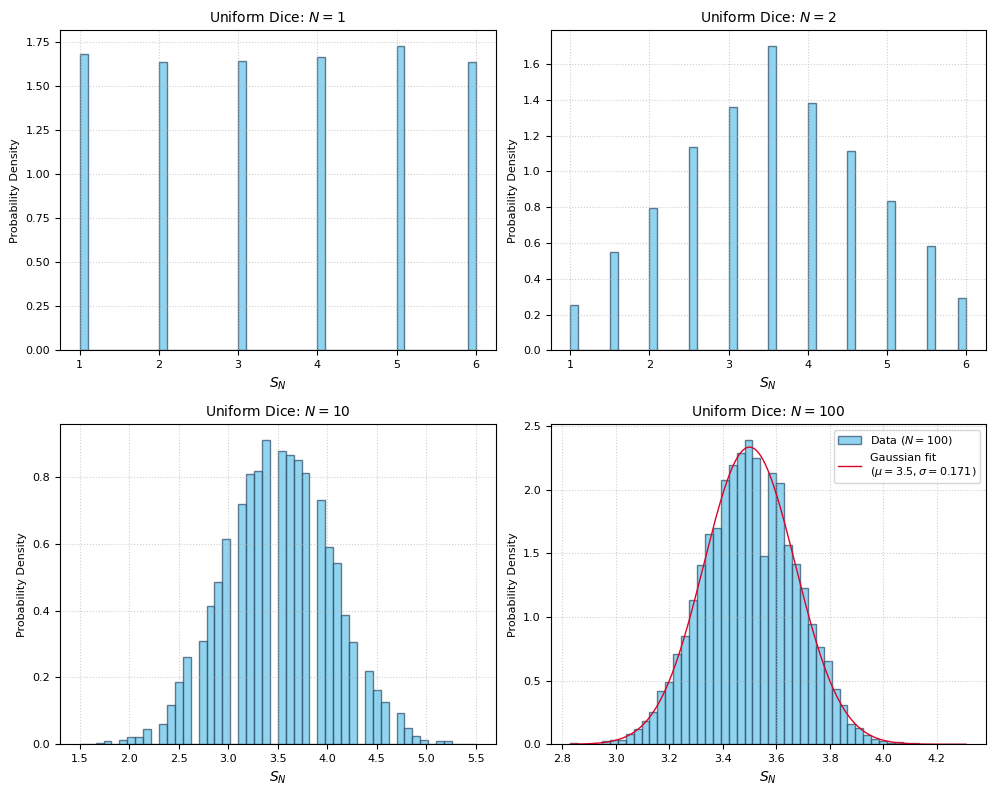

In [9]:
from scipy.stats import norm

plt.figure(figsize=(10, 8))
N_values = [1, 2, 10, 100]

mu_theory = 3.5
var_theory = 35 / 12 

for i, n in enumerate(N_values):
    data = np.loadtxt(f"./OUTPUT/uni_{n}.dat")

    plt.subplot(2, 2, i + 1)
    count, bins, _ = plt.hist(data, bins=50, density=True, color="#63c3e9ff", edgecolor="#2c4a64fb", alpha=0.7, label=f"Data ($N={n}$)")

    if n == 100:
        x_axis = np.linspace(min(data), max(data), 200)
        sigma_N = np.sqrt(var_theory / n)

        plt.plot( x_axis, norm.pdf(x_axis, loc=mu_theory, scale=sigma_N), color="#d90429",linewidth=1,label=f"Gaussian fit\n$(\mu={mu_theory}, \sigma={sigma_N:.3f})$")
        plt.legend(loc="upper right", fontsize=8)

    plt.title(f"Uniform Dice: $N = {n}$", fontsize=10)
    plt.xlabel("$S_N$", fontsize=10)
    plt.ylabel("Probability Density", fontsize=8)
    plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

From the shown histograms we can see how the empirical distribution starts from a flat profile for $N=1$, then transitions to a triangular shape for $N=2$ and ultimately assumes a symmetric, bell-shaped profile as $N$ grows. For $N=100$, the theoretical Gaussian PDF $\mathcal{N}(\mu, \sigma_N^2)$ exhibits a good agreement with the empirical histogram, providing numerical validation of the Central Limit Theorem for uniformly distributed variables.

#### Exponential Distribution

To sample pseudo-random numbers according to an exponential probability density function $p(x) = \lambda e^{-\lambda x}$ (for $x \in [0, \infty)$), we implemented a dedicated method in the generator class based on the Inversion of the Cumulative Distribution Function.

Given a uniform random variable $y \sim U[0, 1)$, the cumulative distribution function $F(x)$ is defined as:
$$F(x) = \int_{0}^{x} \lambda e^{-\lambda x'} \, dx' = 1 - e^{-\lambda x} = y$$
Inverting this expression yields the sampling transformation $x(y)$ that gives us how the generator generates exponentially distributed values:
$$x(y) = -\frac{1}{\lambda} \ln(1 - y)$$

Similarly to the uniform case, we evaluated $10^4$ realizations of the sample mean $S_N$ for $N \in \{1, 2, 10, 100\}$. 

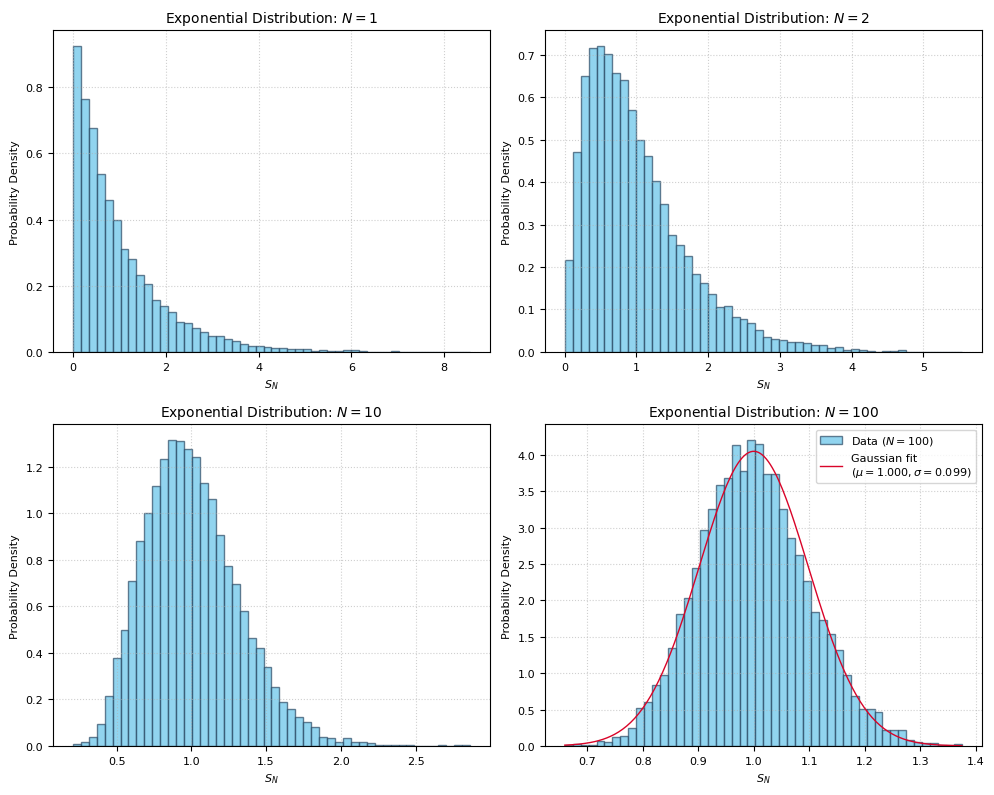

In [10]:
plt.figure(figsize=(10, 8))

for i, n in enumerate(N_values):
    data = np.loadtxt(f"./OUTPUT/exp_{n}.dat")

    plt.subplot(2, 2, i + 1)
    count, bins, _ = plt.hist(data, bins=50, density=True, color="#63c3e9ff", edgecolor="#2c4a64fb", alpha=0.7, label=f"Data ($N={n}$)")

    if n == 100:
        mu_fit, sigma_fit = norm.fit(data)
        x_axis = np.linspace(min(data), max(data), 200)

        plt.plot( x_axis, norm.pdf(x_axis, loc=mu_fit, scale=sigma_fit), color="#d90429",linewidth=1,label=f"Gaussian fit\n$(\mu={mu_fit:.3f}, \sigma={sigma_fit:.3f})$")
        plt.legend(loc="upper right", fontsize=8)

    plt.title(f"Exponential Distribution: $N = {n}$", fontsize=10)
    plt.xlabel("$S_N$", fontsize=8)
    plt.ylabel("Probability Density", fontsize=8)
    plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

From the plotted histograms we can see that while the single-variable distribution ($N=1$) is strongly asymmetric, increasing $N$ quickly smooths the asymmetry of the distribution and finally for $N=100$ the sample mean converges to a symmetric bell shape, matching the fitted Gaussian PDF $\mathcal{N}(\mu, \sigma_N^2)$ and confirming the validity of the Central Limit Theorem for exponentially distributed variables.

#### Cauchy-Lorentz Distribution

As with the exponential distribution, to sample pseudo-random numbers following a Cauchy-Lorentz probability density function centered at $x_0 = 0$ with scale parameter $\Gamma = 1$: 
$$p(x) = \frac{1}{\pi} \frac{\Gamma}{x^2 + \Gamma^2}$$
we implemented the inversion of the Cumulative Distribution Function. Integrating $p(x)$ over the domain $(-\infty, x]$ and equating the result to a uniform random variable $y \sim U[0, 1)$ gives us:
$$F(x) = \int_{-\infty}^{x} \frac{1}{\pi} \frac{\Gamma}{x'^2 + \Gamma^2} \, dx' = \frac{1}{\pi} \arctan\left(\frac{x}{\Gamma}\right) + \frac{1}{2} = y$$
Inverting $F(x)$ explicitly gives the sampling formula for $x(y)$:
$$x(y) = \Gamma \tan\left( \pi \left( y - \frac{1}{2} \right) \right)$$

#### Failure of the CLT and Attractor Property

Unlike the uniform and exponential cases, the Cauchy-Lorentz distribution features tails that decay slowly as $\sim 1/x^2$ for $x \to \pm\infty$. Consequently, its variance diverges to infinity ($\sigma^2 \to \infty$), failing the fundamental hypotheses of the Central Limit Theorem.

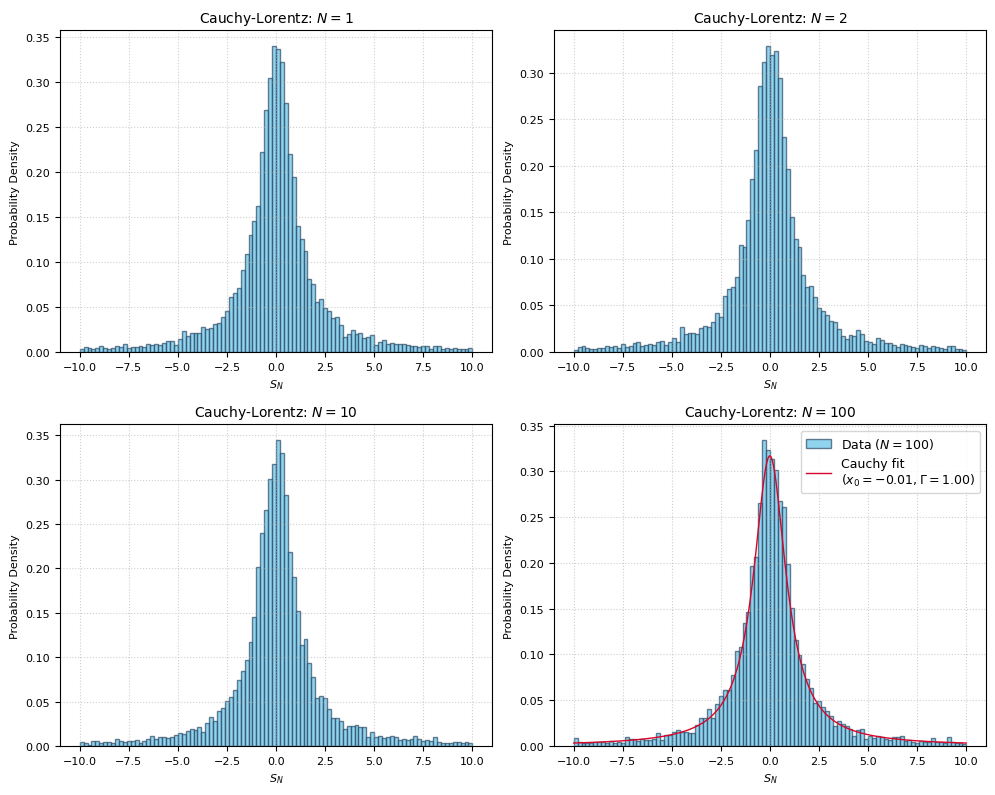

In [11]:
from scipy.stats import cauchy
plt.figure(figsize=(10, 8))
for i, n in enumerate(N_values):
    data = np.loadtxt(f"./OUTPUT/lor_{n}.dat")

    plt.subplot(2, 2, i + 1)
    count, bins, _ = plt.hist(data, bins=100, range=(-10, 10), density=True, color="#63c3e9ff", edgecolor="#2c4a64fb", alpha=0.7, label=f"Data ($N={n}$)")

    if n == 100:

        x0_fit, gamma_fit = cauchy.fit(data)
        x_axis = np.linspace(-10, 10, 300)

        plt.plot( x_axis, cauchy.pdf(x_axis, loc=x0_fit, scale=gamma_fit), color="#d90429", linewidth=1,label=f"Cauchy fit\n($x_0={x0_fit:.2f}, \Gamma={gamma_fit:.2f}$)")
        plt.legend(loc="upper right", fontsize=9)

    plt.title(f"Cauchy-Lorentz: $N = {n}$", fontsize=10)
    plt.xlabel("$S_N$", fontsize=8)
    plt.ylabel("Probability Density", fontsize=8)
    plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

As shown in the histograms, even as $N$ increases from $1$ to $100$, the sample mean $S_N$ does not contract into a Gaussian bell curve. Instead, the profile retains its Lorentzian shape with long tails across all values of $N$. Fitting the $N=100$ histogram with a Cauchy distribution yields a very good result, confirming that the Cauchy-Lorentz distribution acts as its own limit attractor under addition, in full accordance with the generalized central limit theorem for infinite-variance distributions.

## Exercise 1.3

### Buffon's Needle Experiment for Estimating $\pi$

Buffon's needle experiment is a Monte Carlo simulation used to estimate the value of $\pi$: a needle of length $L$ is thrown onto a floor marked with parallel lines at a distance $d$ ($d > L$).

<p align="center">
  <img src="Buffon.png" alt="Buffon setup" width="600"/>
</p>

The probability $P$ that the needle intersects one of the lines is given by:
$$P = \frac{2L}{\pi d}$$
By performing $N_{\text{throws}}$ independent throws and counting the number of hits $N_{\text{hit}}$, the probability can be estimated as $P \approx \frac{N_{\text{hit}}}{N_{\text{throws}}}$. Consequently, $\pi$ can be evaluated empirically as:
$$\pi_{\text{est}} = \frac{2L}{d} \frac{N_{\text{throws}}}{N_{\text{hit}}}$$

To simulate the experiment, we chose a needle length $L = 2$ (so that $L/2 = 1$) and set the parallel lines at $y = 0$ and $y = d$. The vertical position of the needle's center of mass, $y$, was sampled uniformly in the range $[0, d/2]$. We then generated a random orientation $\theta \in [0, \pi/2]$ in space. An intersection with the line $y = 0$ occurs if and only if: 
$y < \frac{L}{2} \sin\theta$

To simulate the angle $\theta$ between the needle and the y lines without assuming the value of $\pi$, we sample points $(x, y)$ uniformly inside the first quadrant of a unit circle using a rejection technique. Points falling outside the unit circle ($x^2 + y^2 > 1$) or at the origin ($x^2 + y^2 = 0$) are rejected. The sine of the orientation angle is then computed directly from the vector coordinates:
$$\sin\theta = \frac{y}{\sqrt{x^2 + y^2}}$$

The corresponding C++ implementation for generating the random orientation is structured as follows:
<small>
```cpp
// Needle orientation 
double x, y, r2;
do {
    x = rnd.Rannyu();
    y = rnd.Rannyu();
    r2 = x * x + y * y;
} while (r2 > 1.0 || r2 == 0.0);

double sin_theta = y / sqrt(r2);


To evaluate the progressive estimation of $\pi$ and its statistical uncertainty, we implemented the data blocking method and plotted the obtained values as a function of the number of blocks. 

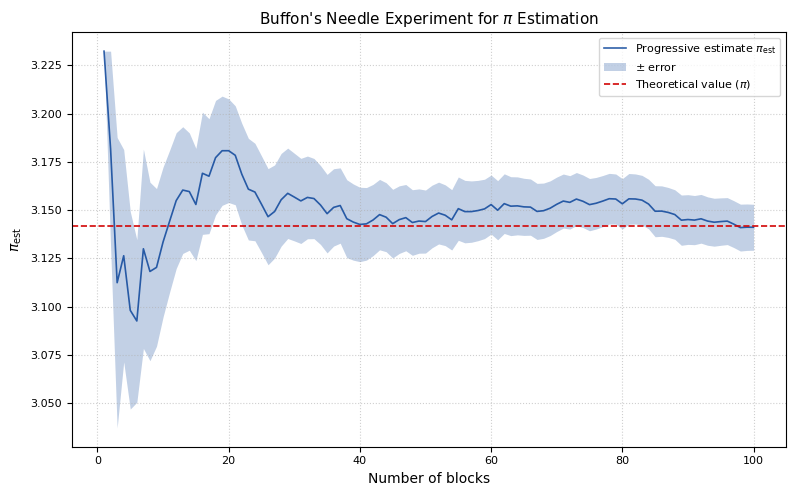

Final estimate of Pi: 3.141168 +/- 0.011894
Compatibility with true value (Z-score): -0.04 sigma


In [12]:
block_buffon, pi_mean, pi_error = np.loadtxt("./OUTPUT/Buffon.dat", unpack=True, comments="#")

plt.figure(figsize=(8, 5))
plt.plot(block_buffon, pi_mean, "-", color="#0c459a", lw=1.2, alpha=0.85, label=r"Progressive estimate $\pi_{\text{est}}$")
plt.fill_between(block_buffon, pi_mean - pi_error, pi_mean + pi_error, color="#0c459a", alpha=0.25, linewidth=0, label=r"$\pm$ error")
plt.axhline(np.pi, color="#d20606", linestyle="--", linewidth=1.2, label=r"Theoretical value ($\pi$)")

plt.xlabel("Number of blocks", fontsize=10)
plt.ylabel(r"$\pi_{\text{est}}$", fontsize=10)
plt.title(r"Buffon's Needle Experiment for $\pi$ Estimation", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Extract the final estimated value and uncertainty from the last block
final_pi = pi_mean[-1]
final_err = pi_error[-1]

# Calculate Z-score: measures deviation from expected value in units of standard deviation
z_score = (final_pi - np.pi) / final_err

print(f"Final estimate of Pi: {final_pi:.6f} +/- {final_err:.6f}")
print(f"Compatibility with true value (Z-score): {z_score:.2f} sigma")

The plot above shows the convergence of the simulation towards the true value of $\pi$. The final estimated value is $\pi_{\text{est}} = 3.141168  \pm 0.011894$, which corresponds to a $Z$-score of $|Z| = 0.04 \sigma$. Since $|Z| < 2$, the result is fully compatible with the theoretical expected value, validating the implementation of the simulation.